# IBM Heron, IBM Nighthawk and Google Willow

These three twins are built from snapshots that IBM and Google publish themselves, not from launch-blog medians:

| Twin | Snapshot | Where the vendor publishes it |
|---|---|---|
| `ibm_heron` | IBM `ibm_boston`, Heron r3, 2026-04-17 | `qiskit-ibm-runtime` fake provider |
| `ibm_nighthawk` | IBM `ibm_miami`, the first Nighthawk, 2026-04-17 | `qiskit-ibm-runtime` fake provider |
| `google_willow` | Google `willow_pink`, 2024-08-16 | `cirq-google` device specification and calibration |

Each one holds the vendor's coupling map, and values for every qubit and coupler. `scripts/import_vendor_snapshots.py`
converted them once, offline. Each twin runs in its own worker container, like the other four.

In [1]:
from qputwin_demo import *

connect()
twins = VENDOR_SNAPSHOT_TWINS
info = {b: device(b) for b in twins}
pd.DataFrame({NAMES[b]: {
    "Qubits": d["n_physical"],
    "Couplers": d["coupling_map"]["n_edges"],
    "Native gates": ", ".join(d["native_gates"]["one_qubit"] + d["native_gates"]["two_qubit"]),
    "Calibration": d["calibration"]["label"],
    "Snapshot": (d["calibration"]["snapshot_date"] or "")[:10],
} for b, d in info.items()}).T

QPUTwin at http://localhost:8000: ready, 7 twins reachable


,Qubits,Couplers,Native gates,Calibration,Snapshot
Heron r3,156,175,"sx, x, rz, cz",IBM Heron r3 - ibm_boston calibration snapshot,2026-04-17
Nighthawk,120,211,"sx, x, rz, cz",IBM Nighthawk r1 - ibm_miami calibration snapshot,2026-04-17
Willow,105,182,"phased_xz, rz, cz",Google Willow - willow_pink calibration snapshot,2024-08-16


## Coupling maps

Heron is a heavy-hex lattice: rows of 16 qubits joined by bridge qubits, so most qubits have two or three neighbours.
Nighthawk is a 12 × 10 square lattice with 218 tunable couplers. Willow is a square grid cut to a diamond, as on
Google's spec sheet. Positions come from each map's `layout`.

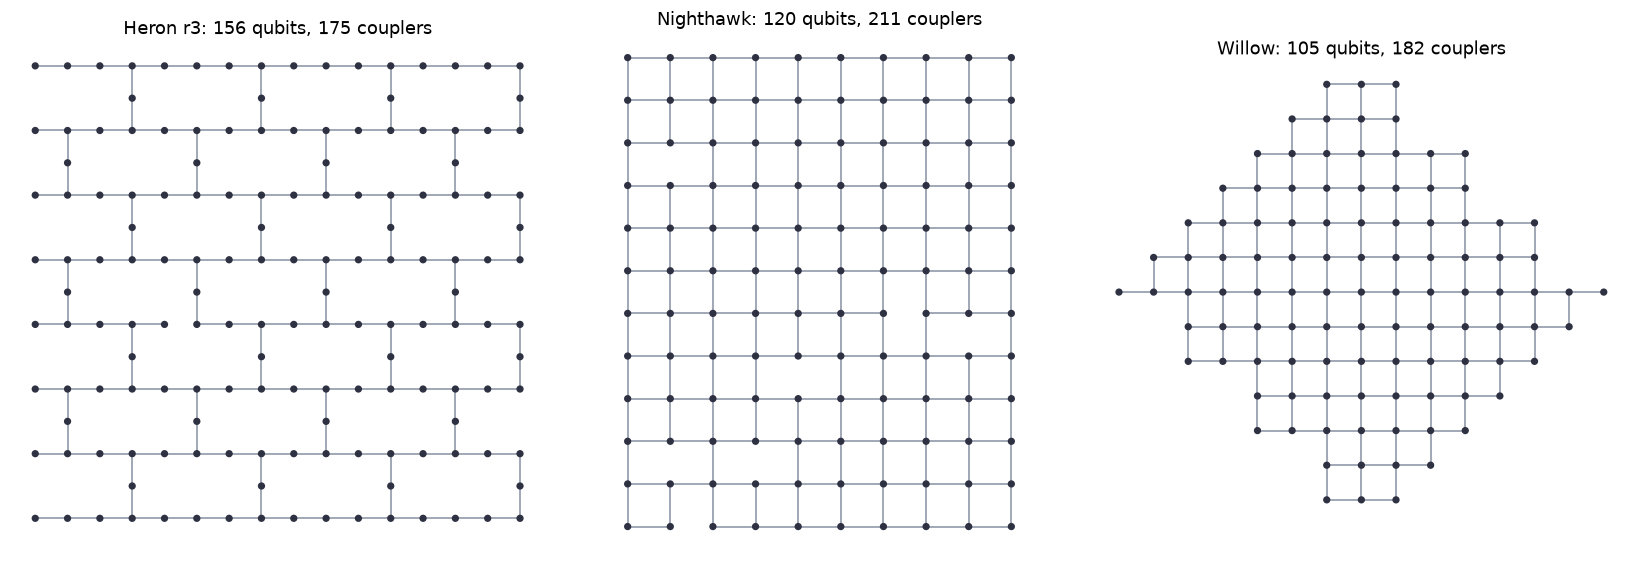

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, backend in zip(axes, twins, strict=True):
    plot_topology(backend, ax=ax)
fig.tight_layout()
plt.show()

IBM marks a coupler that was not working at calibration time with an error of 1. The twins drop those couplers, so a
job that needs one is rejected, as it would fail on the device. Each map lists them.

In [3]:
for backend in ("ibm_heron", "ibm_nighthawk"):
    layout = info[backend]["coupling_map"]["layout"]
    print(f"{NAMES[backend]:10} {layout['system']}: inactive couplers {layout['inactive_couplers']}")

Heron r3   ibm_boston: inactive couplers [[84, 85]]
Nighthawk  ibm_miami: inactive couplers [[21, 31], [66, 67], [68, 78], [74, 84], [91, 101], [93, 103], [111, 112]]


## Every qubit and coupler is calibrated

The API returns device medians and the number of per-qubit and per-coupler overrides. The distributions below are read from
the same packaged files the workers load, and the first line checks that the labels match.

Heron r3   156 qubits and 175 couplers calibrated individually
Nighthawk  120 qubits and 211 couplers calibrated individually
Willow     105 qubits and 182 couplers calibrated individually


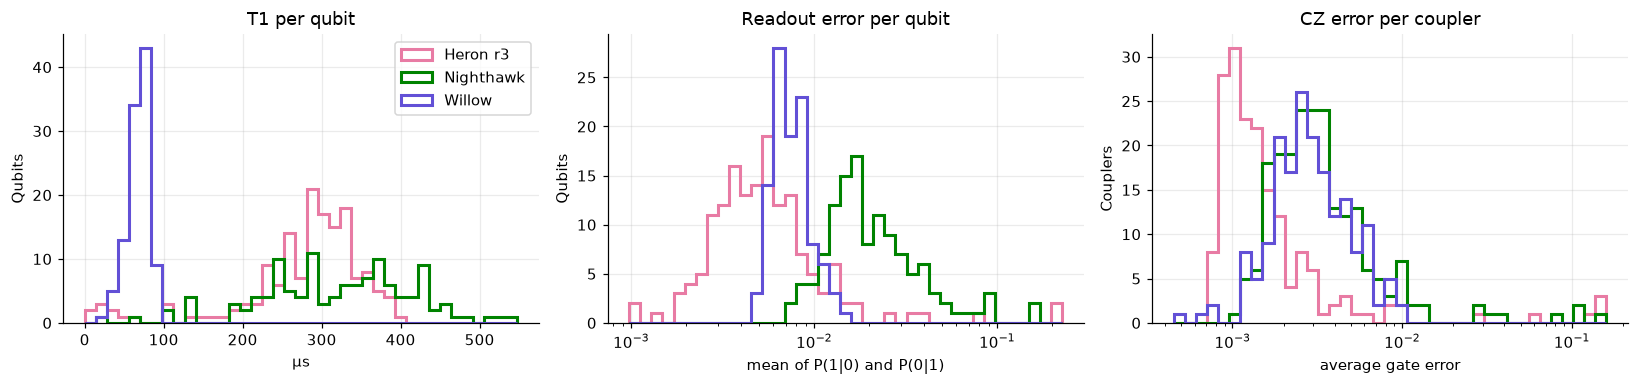

In [4]:
from qputwin_core.devices import DEVICES

for b in twins:
    assert DEVICES[b].calibration.label == info[b]["calibration"]["label"]
    print(f"{NAMES[b]:10} {info[b]['calibration']['qubit_overrides']} qubits and "
          f"{info[b]['calibration']['coupler_overrides']} couplers calibrated individually")

def spread(backend):
    cal = DEVICES[backend].calibration
    t1 = [cal.t1(q) for q in range(DEVICES[backend].n_physical)]
    readout = [sum(cal.readout_errors(q)) / 2 for q in range(DEVICES[backend].n_physical)]
    cz = [1 - cal.gate_fidelity("cz", e) for e in DEVICES[backend].coupling.edges]
    return t1, readout, cz

data = {b: spread(b) for b in twins}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for k, ax in enumerate(axes):
    values = np.concatenate([data[b][k] for b in twins])
    # one set of bins per panel, shared by the three twins; log-spaced for the error rates
    bins = np.linspace(0, values.max(), 40) if k == 0 else np.geomspace(values.min(), values.max(), 40)
    for b in twins:
        ax.hist(data[b][k], bins=bins, histtype="step", linewidth=2, color=COLORS[b], label=NAMES[b])
axes[0].set(title="T1 per qubit", xlabel="µs", ylabel="Qubits")
axes[1].set(title="Readout error per qubit", xlabel="mean of P(1|0) and P(0|1)", ylabel="Qubits", xscale="log")
axes[2].set(title="CZ error per coupler", xlabel="average gate error", ylabel="Couplers", xscale="log")
axes[0].legend()
fig.tight_layout()
plt.show()

## Published or assumed

Almost every number in these twins is published by the vendor. Notebook 01 explains the tags. The few that are not are
listed here: Willow's T2 is derived from Google's RB data with Cirq's formula, and a handful of IBM T2 values above the
physical limit of 2·T1 were clipped.

In [5]:
def provenance_class(note):
    first = note.split(":")[0].split(" ")[0]
    return first if first in ("published", "assumed", "unknown") else "other"

rows = []
for b in twins:
    for field, note in info[b]["calibration"]["provenance"].items():
        rows.append({"Twin": NAMES[b], "Field": field, "Class": provenance_class(note), "Note": note})
notes = pd.DataFrame(rows)
display(notes.groupby(["Twin", "Class"]).size().unstack(fill_value=0))
pd.set_option("display.max_colwidth", 140)
notes[notes.Class != "published"][["Twin", "Field", "Class", "Note"]].set_index(["Twin", "Field"])

Class,assumed,published,unknown
Twin,,,
Heron r3,1,13,1
Nighthawk,2,12,1
Willow,0,10,2


Class  \
Twin      Field                             
Heron r3  feedforward_latency_ns  unknown   
          coherence.t2_clipped    assumed   
Nighthawk reset.duration_ns       assumed   
          feedforward_latency_ns  unknown   
          coherence.t2_clipped    assumed   
Willow    shot_overhead_us        unknown   
          feedforward_latency_ns  unknown   

                                                                                                                                            Note  
Twin      Field                                                                                                                                   
Heron r3  feedforward_latency_ns                                                                          unknown: not published in the snapshot  
          coherence.t2_clipped                                                  assumed: measured T2 > 2*T1 clipped to 2*T1 on qubits [2, 5, 46]  
Nighthawk reset.duration_ns                                              assumed: not in the snapshot (reset is not listed); readout length used  
          feedforward_latency_ns                                                                          unknown: not published in the snapshot  
          coherence.t2_clipped                                                         assumed: measured T2 > 2*T1 clipped to 2*T1 on qubits [6]  
Willow    shot_overhead_us        unknown: not published for this chip (the spec sheet gives 63,000 circuit repetitions/s for the RCS chip only)  
          feedforward_latency_ns                                                                                          unknown: not published

## Native compilation

IBM runs `sx`, `x`, virtual `rz` and `cz`, so a general one-qubit gate costs two `sx` pulses. Willow runs one
`PhasedXZ` microwave pulse with the Z folded in, so the same gate costs one pulse. Qubits 0, 1 and 2 form a coupled
chain on all three chips, so this circuit needs no routing.

In [6]:
circuit = HEADER + """qreg q[3];
creg c[3];
u3(0.4, 1.2, -0.3) q[0];
h q[1];
cx q[1],q[0];
cx q[1],q[2];
rz(pi/5) q[2];
measure q -> c;
"""
compiled = {b: run(b, circuit, shots=4096) for b in twins}
pd.DataFrame({NAMES[b]: r["compilation"]["native_gate_histogram"] for b, r in compiled.items()}).fillna(0).astype(int)

,Heron r3,Nighthawk,Willow
cz,2,2,2
rz,11,11,0
sx,6,6,0
phased_xz,0,0,5


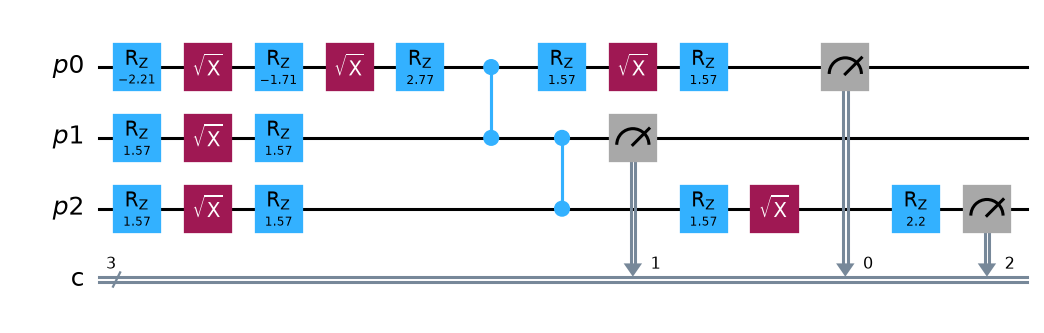

In [7]:
draw_native(compiled["ibm_heron"], circuit)

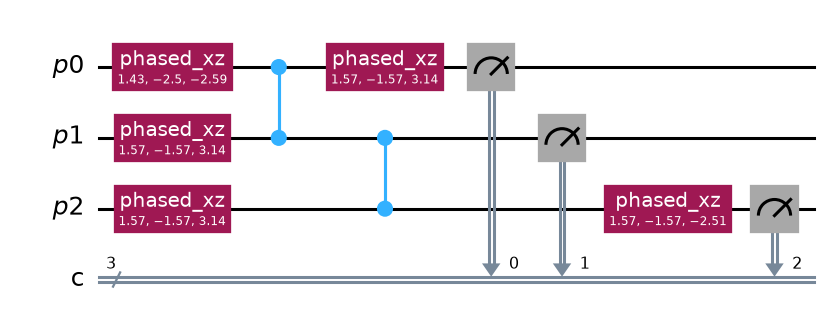

In [8]:
draw_native(compiled["google_willow"], circuit)

## Noise from the snapshots

A GHZ state with calibrated noise, at growing width. `routing=True` lets each twin place the chain on its lattice. These
twins use each qubit's own T1, T2 and readout error and each coupler's own CZ error, so the result depends on which
qubits the router picks. Emerald, which uses device medians, is shown for comparison.

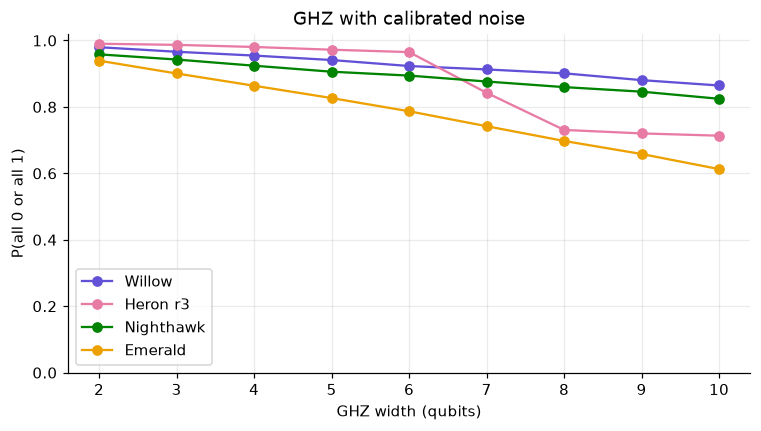

Twin,Emerald,Heron r3,Nighthawk,Willow
Width,,,,
2,0.939,0.990,0.958,0.980
3,0.901,0.987,0.943,0.966
4,0.864,0.980,0.924,0.955
5,0.827,0.972,0.906,0.941
6,0.787,0.965,0.894,0.923
7,0.742,0.843,0.876,0.913
8,0.698,0.731,0.860,0.901
9,0.658,0.720,0.846,0.881
10,0.613,0.713,0.824,0.865


In [9]:
widths = range(2, 11)
rows = []
for backend in [*twins, "iqm_emerald"]:
    for n in widths:
        r = run(backend, ghz(n), noise=True, routing=True, shots=4096)
        rows.append({"Twin": NAMES[backend], "backend": backend, "Width": n,
                     "Measured": success(r, ["0" * n, "1" * n]),
                     "Estimated": r["result"]["noise"]["estimated_success_probability"]})
ghz_rows = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4))
for backend, group in ghz_rows.groupby("backend"):
    ax.plot(group.Width, group.Measured, "o-", color=COLORS[backend], label=NAMES[backend])
ax.set(xlabel="GHZ width (qubits)", ylabel="P(all 0 or all 1)", title="GHZ with calibrated noise", ylim=(0, 1.02))
ax.legend()
plt.show()
ghz_rows.pivot(index="Width", columns="Twin", values="Measured").round(3)

### Why Heron drops at width 7

Per-qubit data matters. The router places qubits by connectivity only, not by error rate. At width 7 it adds a qubit that
IBM's snapshot shows was poor that day. IBM's own transpiler would usually route around it with a noise-aware layout.
A twin built from device medians, like Emerald, cannot show this.

In [10]:
cal = DEVICES["ibm_heron"].calibration
for n in (6, 7):
    r = run("ibm_heron", ghz(n), noise=True, routing=True, shots=4096)
    used = r["compilation"]["physical_qubits_used"]
    print(f"width {n}: qubits {used}, success {success(r, ['0' * n, '1' * n]):.3f}")
worst = min(used, key=cal.t1)
print(f"qubit {worst}: T1 {cal.t1(worst):.1f} µs (median {cal.t1_us:.0f}), "
      f"readout error {sum(cal.readout_errors(worst)) / 2:.3f} (median {(cal.readout_p01 + cal.readout_p10) / 2:.4f})")

width 6: qubits [47, 57, 67, 68, 69, 70], success 0.965
width 7: qubits [46, 47, 57, 67, 68, 69, 70], success 0.843
qubit 46: T1 8.4 µs (median 292), readout error 0.082 (median 0.0044)


## Hardware time, including IBM's repetition delay

IBM publishes the wait between shots (`default_rep_delay`): 250 µs on Heron and 4 ms on Nighthawk. The IBM twins add it to
every shot. Google publishes no per-shot overhead for this chip, so the Willow estimate covers the circuit alone, and
says so. Durations here are all published.

In [11]:
rows = {}
for b in twins:
    est = run(b, ghz(5), routing=True, shots=1000)["compilation"]["hardware_time_estimate"]
    rows[NAMES[b]] = {"Circuit per shot (µs)": est["circuit_duration_us"],
                      "Overhead per shot (µs)": est["shot_overhead_us"],
                      "Includes overhead": est["includes_shot_overhead"],
                      "1000 shots (s)": round(est["estimated_job_duration_s"], 4),
                      "Assumed durations": ", ".join(est["assumed_parameters"]) or "none"}
pd.DataFrame(rows).T

,Circuit per shot (µs),Overhead per shot (µs),Includes overhead,1000 shots (s),Assumed durations
Heron r3,2.632,250.0,True,0.2526,none
Nighthawk,3.272,4000.0,True,4.0033,none
Willow,0.893,None,False,0.0009,none


## Checked against the vendors' own tools

These checks need `qiskit-ibm-runtime`, `qiskit-aer` and `cirq-google`, which this environment does not install. They live in
`comparison/run_comparison.py vendor_xval`, and the results are in `docs/research/simulator-comparison.md`:

* every gate the twins emit after routing is legal in IBM's `Target` for `ibm_boston` and `ibm_miami`, and every routed
  Willow circuit passes Cirq's `willow_pink` device validation; the coupling maps equal the vendors' maps, minus IBM's
  inactive couplers;
* compiled circuits equal their sources to about 1e-15;
* run unchanged on the same physical qubits, 33 circuits per twin reproduce the vendors' own noise models of the same
  snapshots to a median fidelity difference of 0.0012 (Heron), 0.0041 (Nighthawk) and 0.0013 (Willow), at most 0.021;
* a twin built from device medians differs from IBM's model by up to 0.68 on the same circuits, because medians cannot
  see the poor qubits that the router lands on, like qubit 46 above.

These compare against the vendors' published models. None of the twins has been validated against hardware.